# AI SCI 290A Project 1: Weather Prediction
Using ERA5 data

# 1. Imports

In [123]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import seaborn as sns
import glob
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 2. Preliminary Exploration

In [124]:
DATA_DIR = "./data/"

In [125]:
temp_files = sorted(
    glob.glob(f"{DATA_DIR}/**/*.nc", recursive=True)
)
ds = xr.open_mfdataset(
    temp_files,
    combine="by_coords"
)

## Avg temp

Text(0.5, 1.0, 'Mean 2m temp')

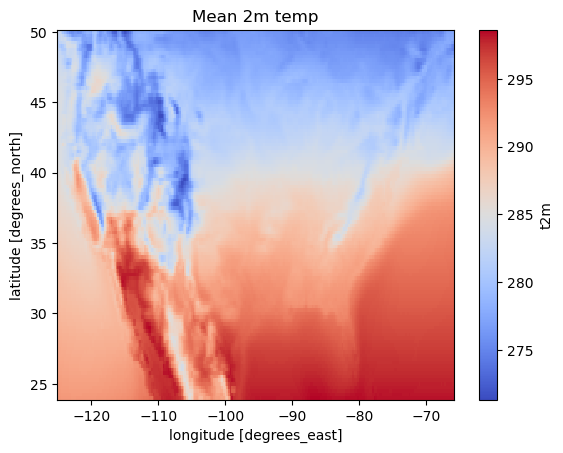

In [126]:
fig, ax = plt.subplots()
ds.t2m.mean(dim="valid_time").plot(cmap="coolwarm")
ax.set_title("Mean 2m temp")

## Temperature over time at UC Irvine

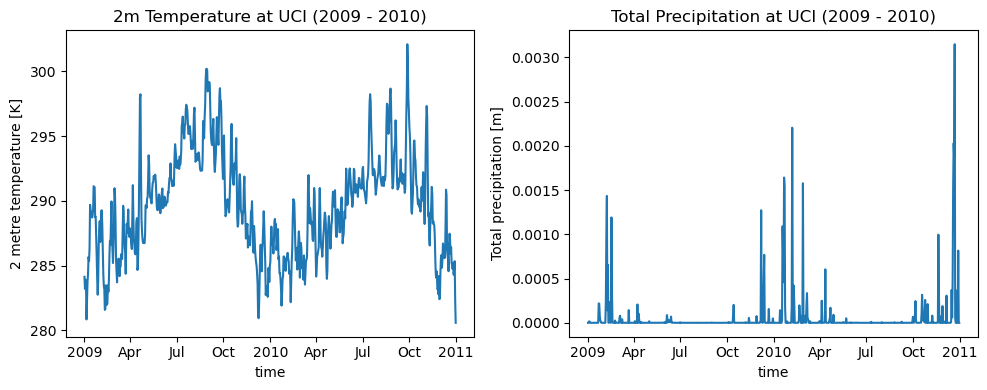

In [127]:
lat_uci = 33.64
lon_uci = -117.84

ds_uci = ds.sel(latitude=lat_uci, longitude=lon_uci, method="nearest")

fig, axs = plt.subplots(
    ncols=2,
    figsize=(10, 4)
)
ds_uci.t2m.plot(ax=axs[0])
axs[0].set_title("2m Temperature at UCI (2009 - 2010)")

ds_uci.tp.plot(ax=axs[1])
axs[1].set_title("Total Precipitation at UCI (2009 - 2010)")

fig.tight_layout()

## Feature Engineering

In [128]:
# Calcs and adds 3 and 7 day rolling average and previous day columns
ds_uci['rolling_3'] = ds_uci['t2m'].shift(valid_time=1).rolling(valid_time=3).mean()  # up to today
ds_uci['rolling_7'] = ds_uci['t2m'].shift(valid_time=1).rolling(valid_time=7).mean()
ds_uci['prev_day'] = ds_uci['t2m'].shift(valid_time=1)  # yesterday's temp

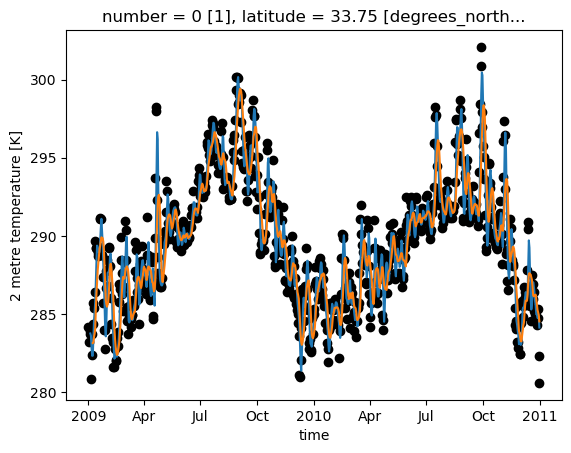

In [129]:
fig, ax = plt.subplots()

ds_uci["t2m"].plot.scatter("valid_time", color="black")
ds_uci["rolling_3"].plot()
ds_uci["rolling_7"].plot()

# 3. Set up ML methods

In [130]:
# Prep for regression by deleting nan rows
ds_uci = ds_uci.dropna(dim="valid_time")
n_samples = len(ds_uci["valid_time"])

In [131]:
# Test train split
X = ds_uci.to_dataframe()[["prev_day", "rolling_3", "rolling_7", "v10", "u10", "msl", "tp"]]
y = ds_uci["t2m"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=210, shuffle=False, test_size=0.15)

In [132]:
# Data rescaling

X_scaler = StandardScaler().fit(X_train)

X_train_sc = X_scaler.transform(X_train)
X_test_sc = X_scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_clean = y_train.reshape(-1, 1)

y_scaler.fit(y_train_clean)
y_train_sc = y_scaler.transform(y_train_clean)
y_test_sc = y_scaler.transform(y_test.reshape(-1, 1))

## Linear Regression
Predicts using a 3-day rolling average, 7-day rolling average, and the previous day's temperature.

### Predictors: Previous Day, 3-Day Rolling, and 7-Day Rolling

In [133]:
reg = LinearRegression()
reg.fit(X_train_sc, y_train_sc)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [134]:
y_pred = reg.predict(X_test_sc)

mae = mean_absolute_error(y_test_sc, y_pred)
mse = mean_squared_error(y_test_sc, y_pred)
rmse = np.sqrt(mean_squared_error(y_test_sc, y_pred))
r2 = r2_score(y_test_sc, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE:  {rmse:.3f}")
print(f"R²:   {r2:.3f}")

'''fig, ax = plt.subplots()
ax.scatter(x=y_test_sc, y=y_pred)
ax.set_xlabel("Scaled True Temp")
ax.set_ylabel("Scaled Predicted Temp")'''

MAE:  0.276
MSE:  0.121
RMSE:  0.348
R²:   0.897


'fig, ax = plt.subplots()\nax.scatter(x=y_test_sc, y=y_pred)\nax.set_xlabel("Scaled True Temp")\nax.set_ylabel("Scaled Predicted Temp")'

## Neural Network  

In [135]:
reg = MLPRegressor(hidden_layer_sizes=(1000,))
reg.fit(X_train_sc, y_train_sc)

/Users/adambrower/miniforge3/envs/290A/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:1771: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,loss,'squared_error'
,hidden_layer_sizes,"(1000,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True


In [136]:
y_pred = reg.predict(X_test_sc)

mae = mean_absolute_error(y_test_sc, y_pred)
mse = mean_squared_error(y_test_sc, y_pred)
rmse = np.sqrt(mean_squared_error(y_test_sc, y_pred))
r2 = r2_score(y_test_sc, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE:  {rmse:.3f}")
print(f"R²:   {r2:.3f}")
'''
fig, ax = plt.subplots()
ax.scatter(y_test_sc, y_pred)
ax.set_xlabel("Scaled True Temp")
ax.set_ylabel("Scaled Predicted Temp")'''

MAE:  0.263
MSE:  0.120
RMSE:  0.346
R²:   0.898


'\nfig, ax = plt.subplots()\nax.scatter(y_test_sc, y_pred)\nax.set_xlabel("Scaled True Temp")\nax.set_ylabel("Scaled Predicted Temp")'